# MEMBER6 - Feature Engineering - Dimensionality Reduction (PCA)

**Dataset:** Ames Housing (`train.csv`, 1,460 houses, 79 features + `SalePrice`)  
**Task:** predict the sale price of a house (regression).  
Run this notebook from the `notebooks/` folder so the `../data/raw/` paths resolve.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
%matplotlib inline

df = pd.read_csv('../data/raw/train.csv')
test = pd.read_csv('../data/raw/test.csv')
print('train:', df.shape, '| test:', test.shape)
df.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Prepare numeric features (median fill + standardisation)

PCA is variance-based, so features must be standardised first. Only numeric columns are used here (categoricals would need encoding).

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df.drop(columns=['Id', 'SalePrice', 'MSSubClass']).select_dtypes(include='number')
y_log = np.log1p(df['SalePrice'])
X_scaled = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(X))
print('Matrix:', X_scaled.shape)

Matrix: (1460, 35)


## 2. Fit PCA and inspect explained variance

In [3]:
pca_full = PCA(random_state=42).fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90 = int(np.argmax(cum >= 0.90) + 1); n95 = int(np.argmax(cum >= 0.95) + 1)
print('PC1 + PC2 explain', round(cum[1] * 100, 1), '% of variance')
print('Components needed for 90 % variance:', n90, '| for 95 %:', n95, '| original features:', X.shape[1])
loadings = pd.DataFrame(pca_full.components_[:2].T, index=X.columns, columns=['PC1', 'PC2'])
display(loadings.reindex(loadings['PC1'].abs().sort_values(ascending=False).index).head(8).round(3))

PC1 + PC2 explain 29.4 % of variance
Components needed for 90 % variance: 22 | for 95 %: 25 | original features: 35


,PC1,PC2
OverallQual,0.302,-0.030
GrLivArea,0.300,0.263
GarageCars,0.283,-0.076
GarageArea,0.279,-0.103
FullBath,0.263,0.136
TotalBsmtSF,0.258,-0.190
1stFlrSF,0.257,-0.126
TotRmsAbvGrd,0.241,0.341


## 3. EDA visualizations

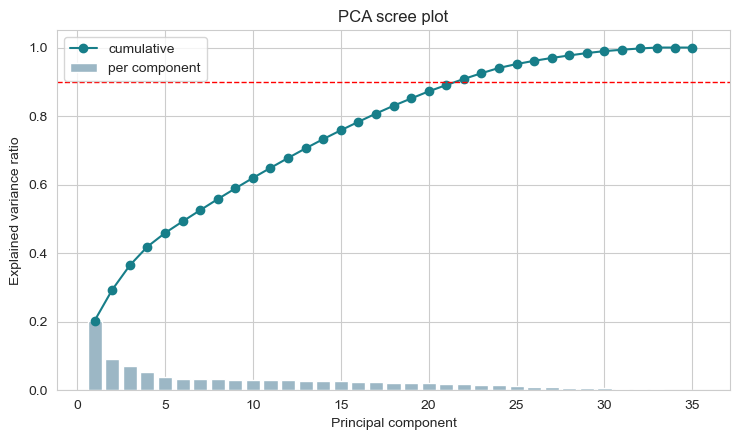

In [4]:
os.makedirs('../results/eda_visualizations/PCA', exist_ok=True)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color='#9CB7C5', label='per component')
ax.plot(range(1, len(cum) + 1), cum, 'o-', color='#177E89', label='cumulative')
ax.axhline(0.90, ls='--', color='red', lw=1); ax.set_xlabel('Principal component'); ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA scree plot'); ax.legend()
plt.tight_layout(); plt.savefig('../results/eda_visualizations/PCA/pca_variance.png', dpi=120); plt.show()

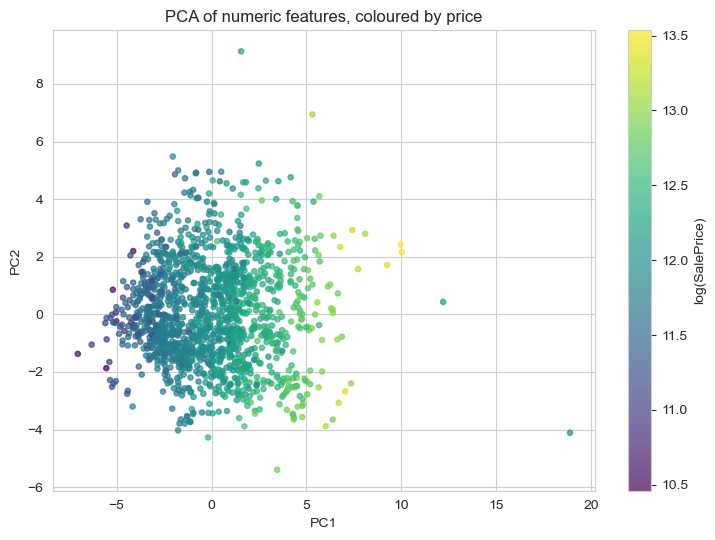

In [5]:
comp = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
plt.figure(figsize=(7.5, 5.5))
sc = plt.scatter(comp[:, 0], comp[:, 1], c=y_log, cmap='viridis', s=14, alpha=0.7)
plt.colorbar(sc, label='log(SalePrice)'); plt.xlabel('PC1'); plt.ylabel('PC2')
plt.title('PCA of numeric features, coloured by price')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/PCA/pca_scatter.png', dpi=120); plt.show()

## 4. How many components are enough? (Ridge, 5-fold CV RMSLE)

2     0.1821
5     0.1719
10    0.1710
15    0.1694
20    0.1643
35    0.1607
dtype: float64


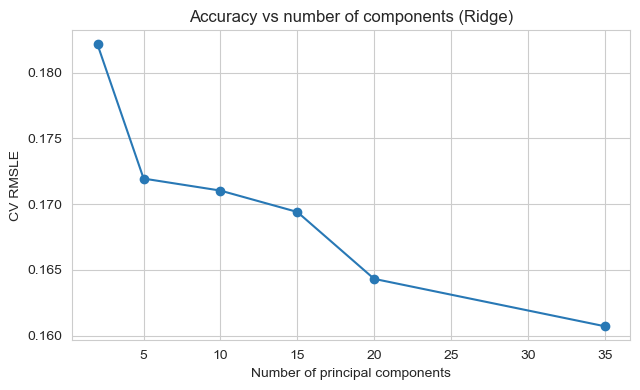

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, KFold
cv = KFold(5, shuffle=True, random_state=42)
ks = [2, 5, 10, 15, 20, X.shape[1]]
scores = []
for k in ks:
    p = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), PCA(n_components=k, random_state=42), Ridge(alpha=10))
    scores.append(-cross_val_score(p, X, y_log, cv=cv, scoring='neg_root_mean_squared_error').mean())
curve = pd.Series(scores, index=ks).round(4); print(curve)
plt.figure(figsize=(6.5, 4)); plt.plot(ks, scores, 'o-', color='#2878B5')
plt.xlabel('Number of principal components'); plt.ylabel('CV RMSLE'); plt.title('Accuracy vs number of components (Ridge)')
plt.tight_layout(); plt.savefig('../results/eda_visualizations/PCA/components_vs_error.png', dpi=120); plt.show()

### Interpretation

The first two components explain only about 29 % of the variance, so the 2-D scatter is an exploratory view, not proof of separability; even so, the colour gradient from low to high price along PC1 shows that the numeric size/quality features together carry a strong price signal (PC1 is dominated by `OverallQual`, `GrLivArea` and the garage/basement sizes). **22 of the 35** possible components are needed to keep 90 % of the variance, so redundancy is moderate. The component-vs-error curve is the key result: error falls steadily as components are added (RMSLE 0.182 with 2 components, 0.164 with 20, 0.161 with all 35), so PCA does **not** improve accuracy here; it only compresses the data. PCA components are also hard to interpret (each mixes many features), so the model notebooks keep the original features and use regularisation or trees instead of PCA.